- First check for impossible outliers.
- Then fill in missing values using the IterativeImputer.
- Standard Scaling.

In [73]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
data = pd.read_csv("../../preliminar_phase_submision/training_data/SyntheticData_Training.csv")
target = "inhospital_mortality"

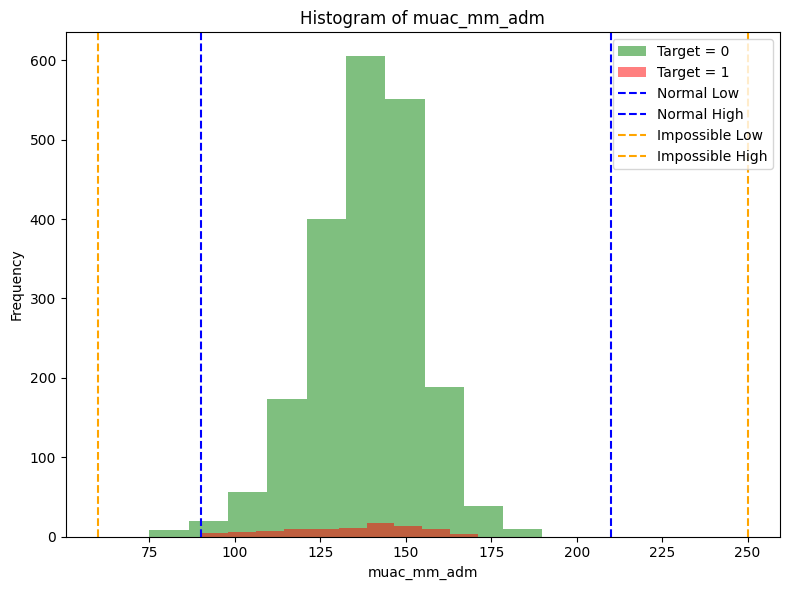

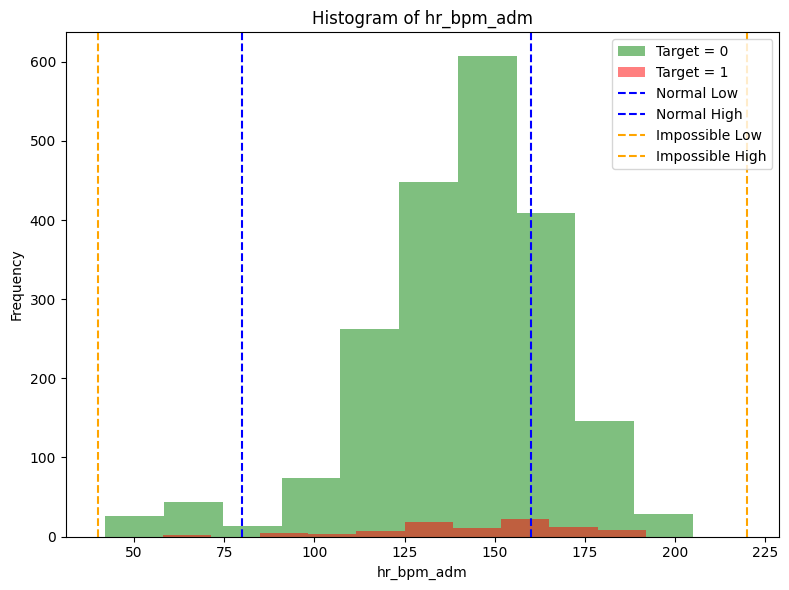

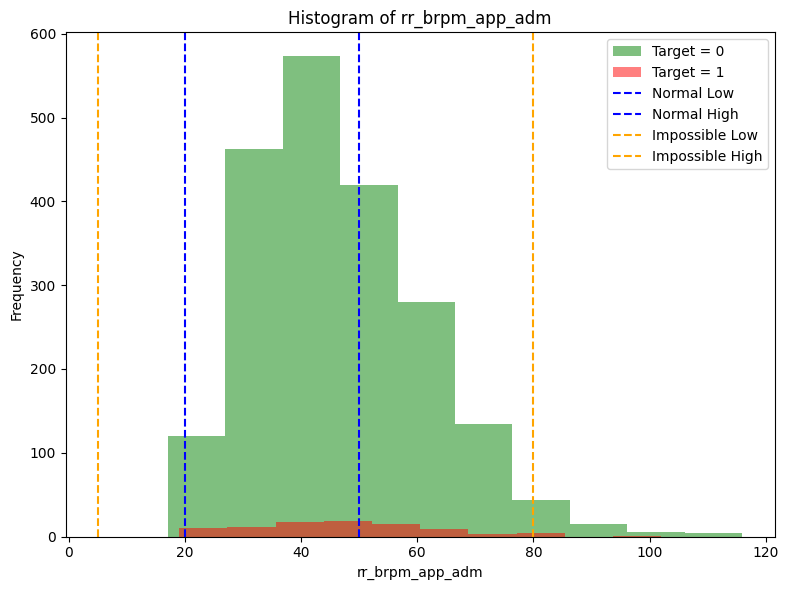

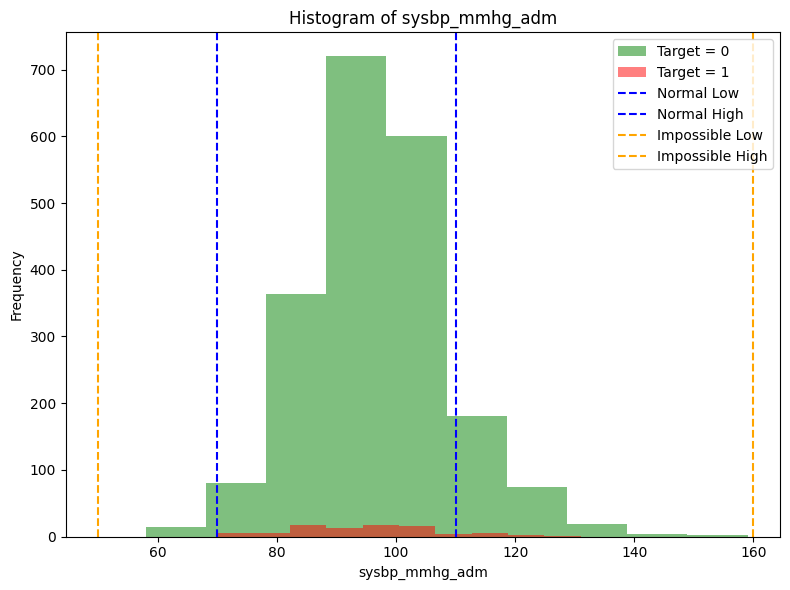

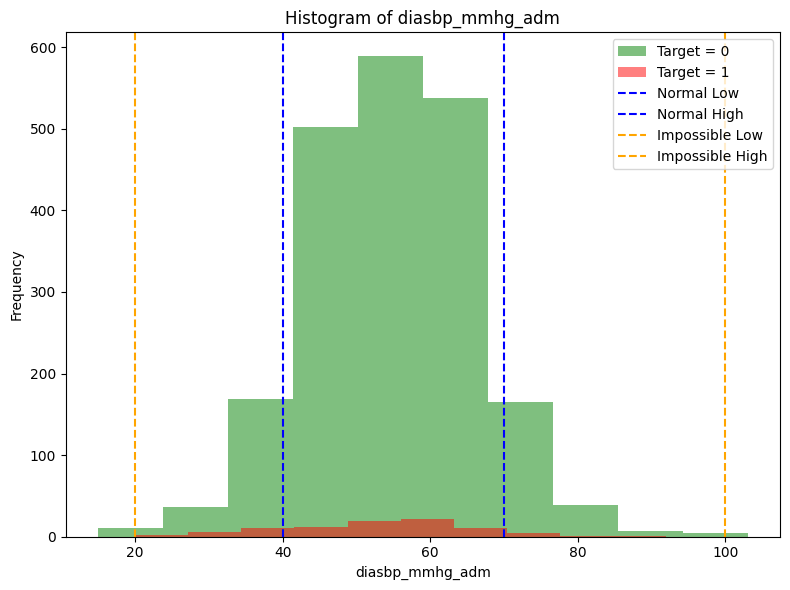

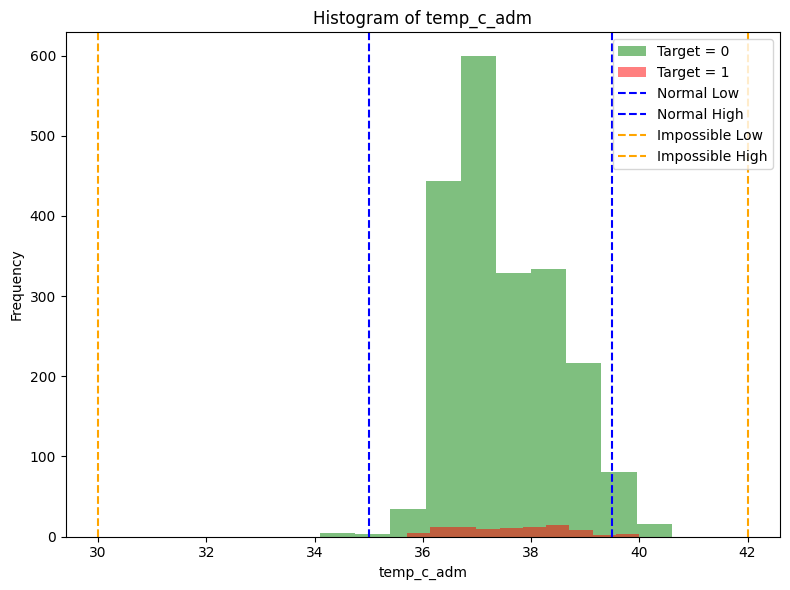

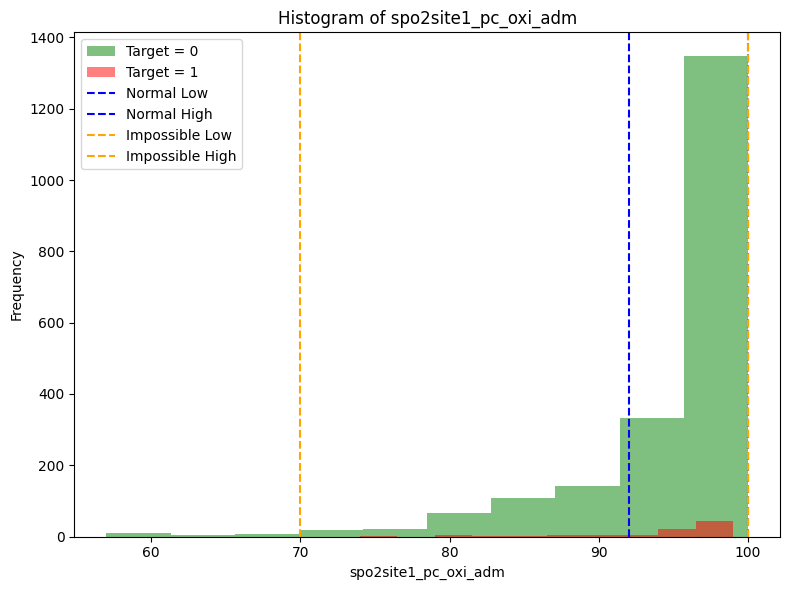

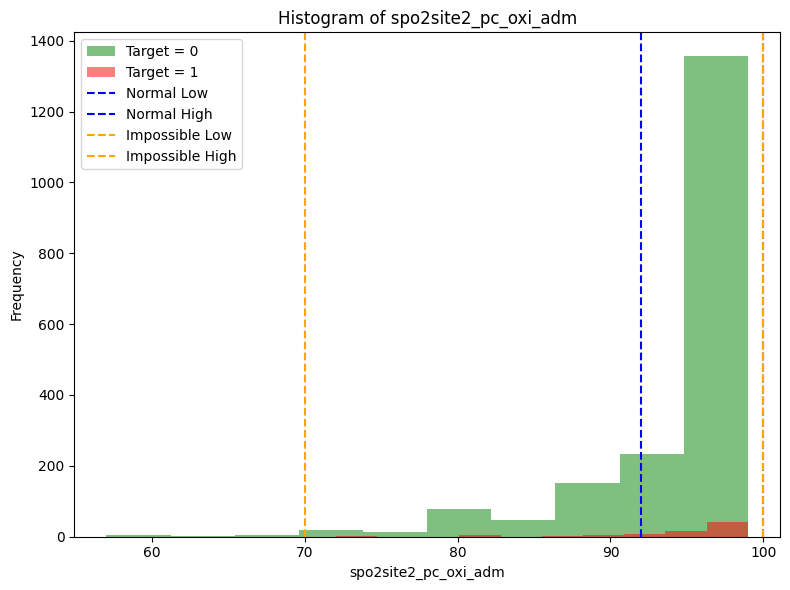

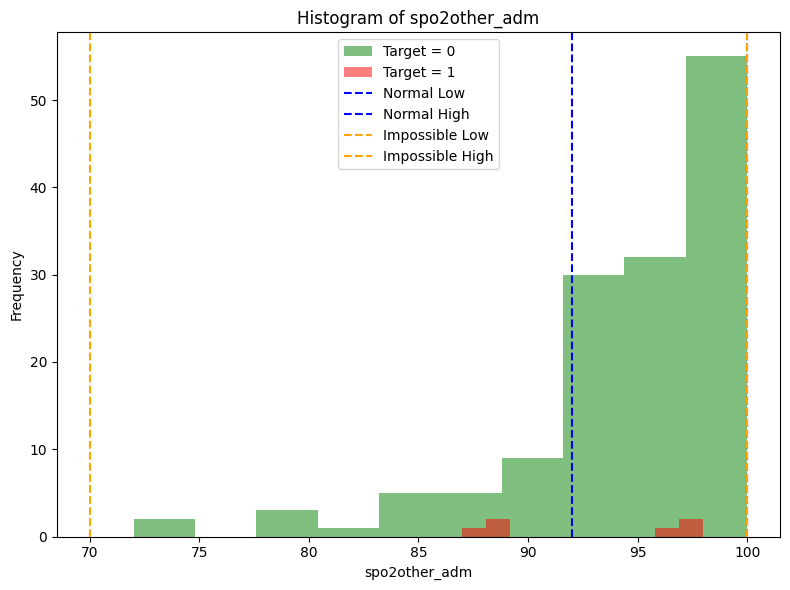

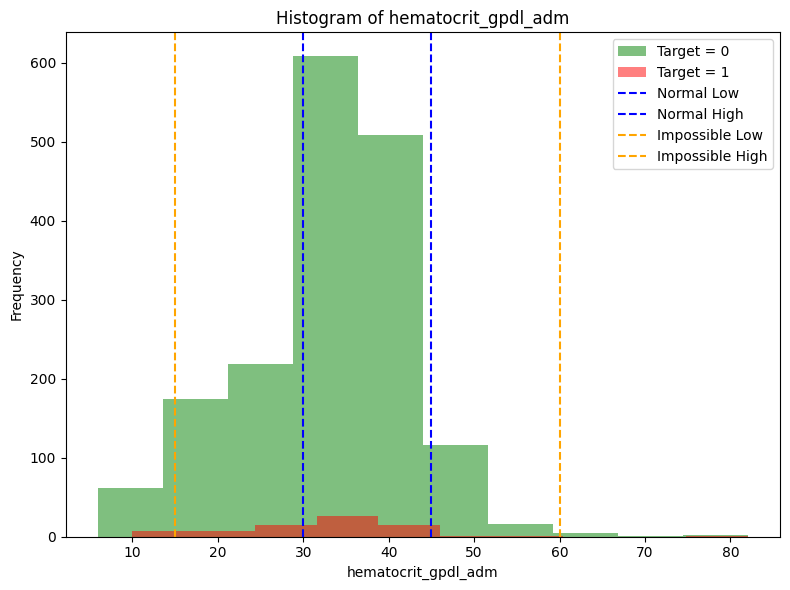

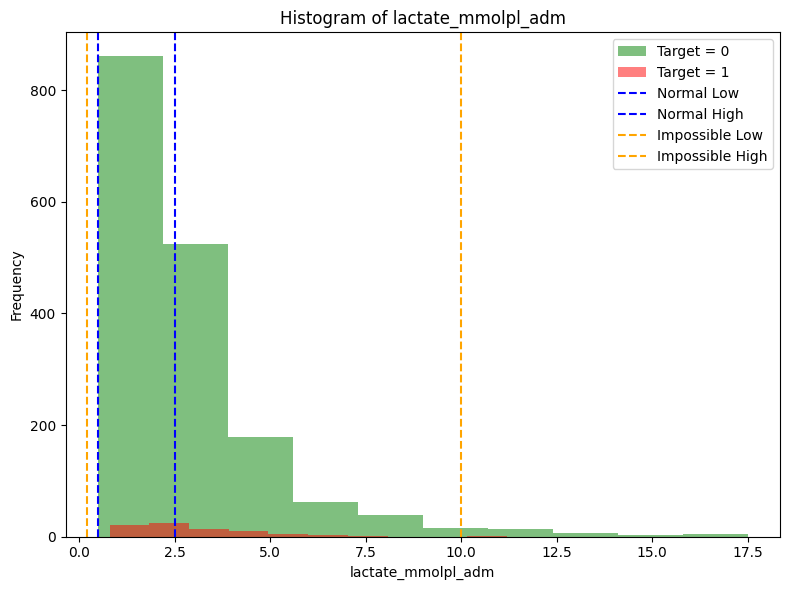

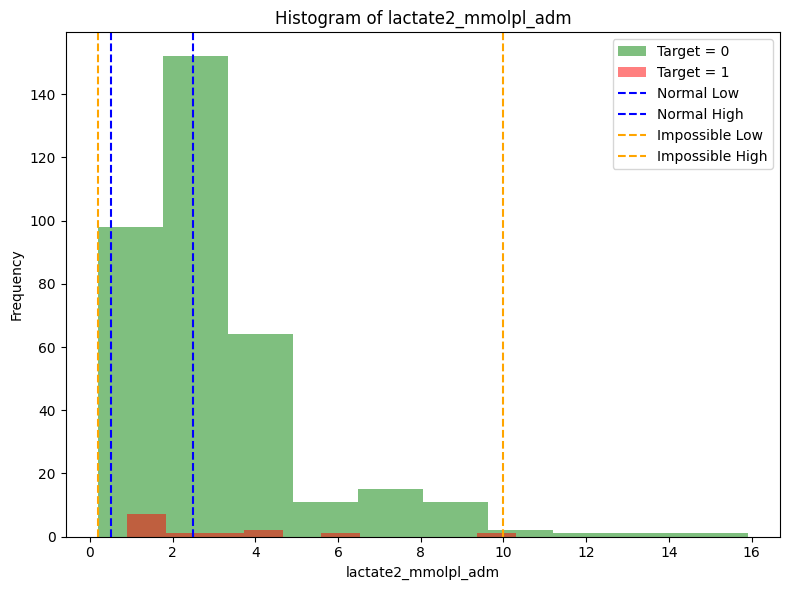

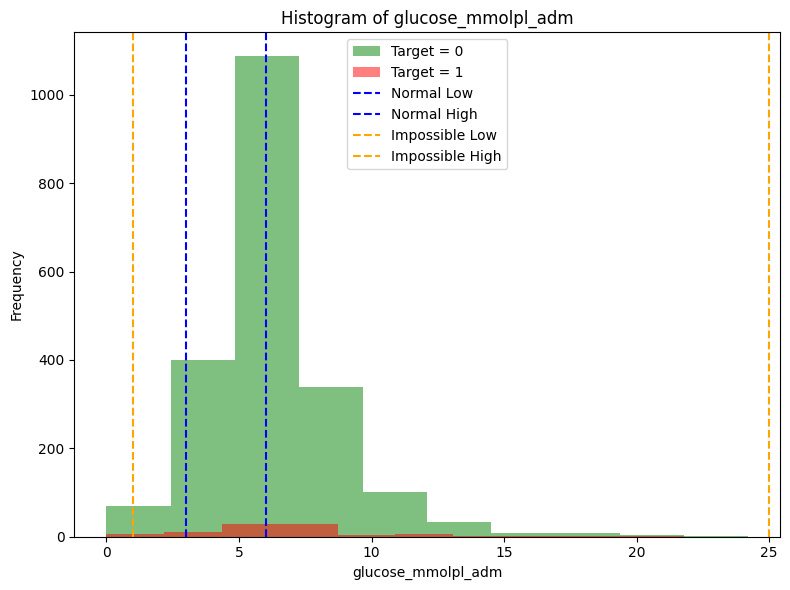

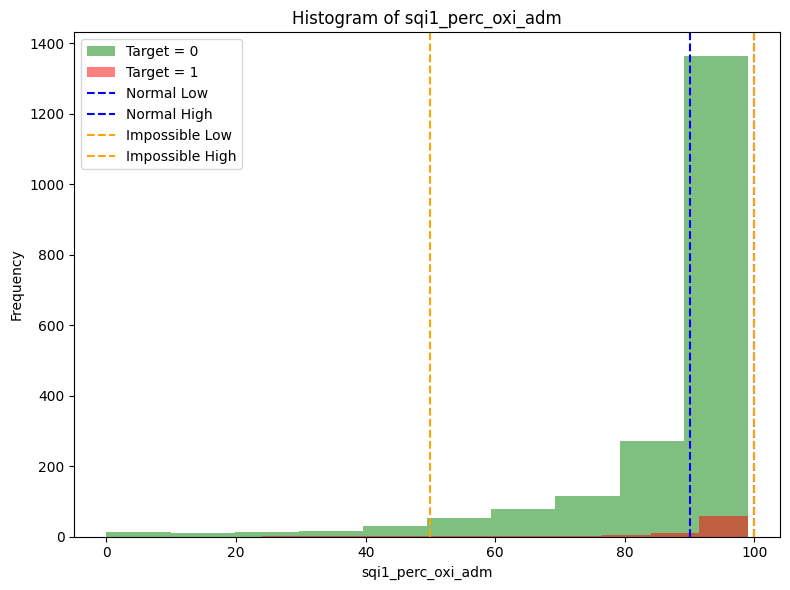

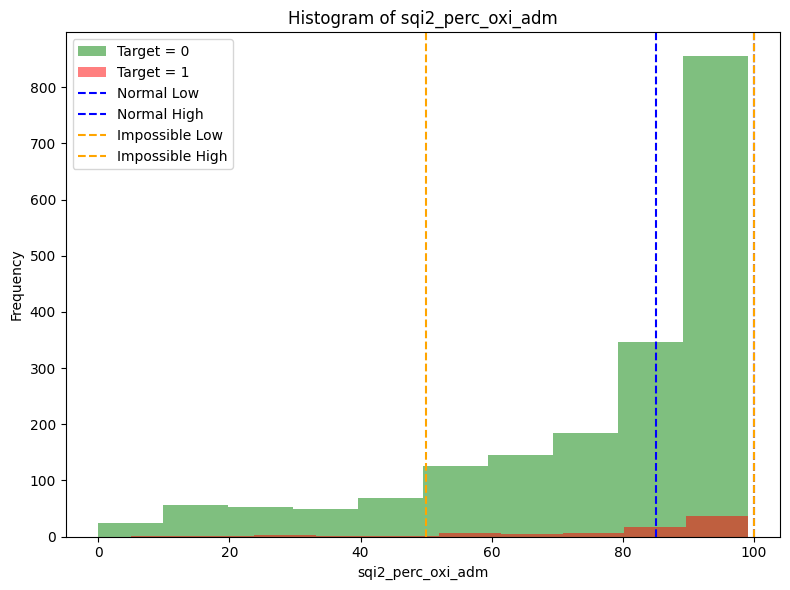

In [168]:
data = pd.concat([df, data[target]], axis=1)
fringe_boundaries = pd.read_csv("fringe boundaries.csv")

def plot_outliers(data, fringe_boundaries, target=target):
    for col in data.columns:
        if col in fringe_boundaries['Measurement'].values:  # Use .values for faster lookup
            fig, ax = plt.subplots(figsize=(8, 6))

            # Plot histograms for target=0 and target=1
            for target_val, color in [(0, 'green'), (1, 'red')]:
                subset = data[data[target] == target_val][col]
                # Handle NaN values explicitly:
                subset = subset.dropna()  # Or fillna if you prefer
                ax.hist(subset, alpha=0.5, color=color, label=f'Target = {target_val}')

            # Add boundary lines
            boundaries = fringe_boundaries[fringe_boundaries['Measurement'] == col].iloc[0]
            ax.axvline(boundaries['Normal Low'], color='blue', linestyle='--', label='Normal Low')
            ax.axvline(boundaries['Normal High'], color='blue', linestyle='--', label='Normal High')
            ax.axvline(boundaries['Impossible Low'], color='orange', linestyle='--', label='Impossible Low')
            ax.axvline(boundaries['Impossible High'], color='orange', linestyle='--', label='Impossible High')

            ax.set_title(f'Histogram of {col}')
            ax.set_xlabel(col)
            ax.set_ylabel('Frequency')
            ax.legend()
            plt.tight_layout() # Adjust layout to prevent labels from overlapping
            plt.show()
plot_outliers(data, fringe_boundaries)

In [161]:
def trim_outliers(data, fringe_boundaries):
    """
    Trims outliers in the data based on fringe boundaries.

    Args:
        data: The Pandas DataFrame containing the data and target column.
        fringe_boundaries: The Pandas DataFrame containing the fringe boundaries.

    Returns:
        The modified Pandas DataFrame with outliers clipped.
    """
    data = data.copy()


    for col in data.columns:
        if col in fringe_boundaries['col'].values:
            boundaries = fringe_boundaries[fringe_boundaries['col'] == col].iloc[0]
            fringe_low = boundaries['fringe_low']
            fringe_high = boundaries['fringe_high']

            for index, row in data.iterrows(): # changed from itertuples to iterrows for easier indexing.
                value = row[col]

                if pd.isna(value): #skip if NaN
                    continue

                if value < fringe_low:
                    data.loc[index, col] = fringe_low
                elif value > fringe_high:
                    data.loc[index, col] = fringe_high

    return data

In [173]:
import pandas as pd
import numpy as np

def trim_outliers(data, fringe_boundaries, target_col):
    """
    Trims outliers in the data based on fringe boundaries.

    Args:
        data: The Pandas DataFrame containing the data and target column.
        fringe_boundaries: The Pandas DataFrame containing the fringe boundaries.

    Returns:
        The modified Pandas DataFrame with outliers trimmed.
    """

    data['Outlier_trimmed'] = False  # Initialize the new column

    rows_to_drop = []  # List to store indices of rows to drop (target=0 outliers)

    for col in data.columns:
        if col in fringe_boundaries['Measurement'].values:
            boundaries = fringe_boundaries[fringe_boundaries['Measurement'] == col].iloc[0]
            fringe_low = boundaries['Impossible Low']
            fringe_high = boundaries['Impossible High']

            for index, row in data.iterrows(): # changed from itertuples to iterrows for easier indexing.
                value = row[col]
                target = row[target_col]

                if pd.isna(value): #skip if NaN
                    continue

                if value < fringe_low or value > fringe_high:
                    if target == 0:
                        rows_to_drop.append(index)
                    elif target == 1:
                        if value < fringe_low:
                            data.loc[index, col] = fringe_low
                        else:
                            data.loc[index, col] = fringe_high
                        data.loc[index, 'Outlier_trimmed'] = True

    # Drop rows with target=0 outliers efficiently
    data = data.drop(rows_to_drop)

    return data

In [178]:
tmp = trim_outliers(data, fringe_boundaries, target)
display(data[target].value_counts())
display(tmp[target].value_counts())

inhospital_mortality
0    2060
1      88
Name: count, dtype: int64

inhospital_mortality
0    1623
1      88
Name: count, dtype: int64

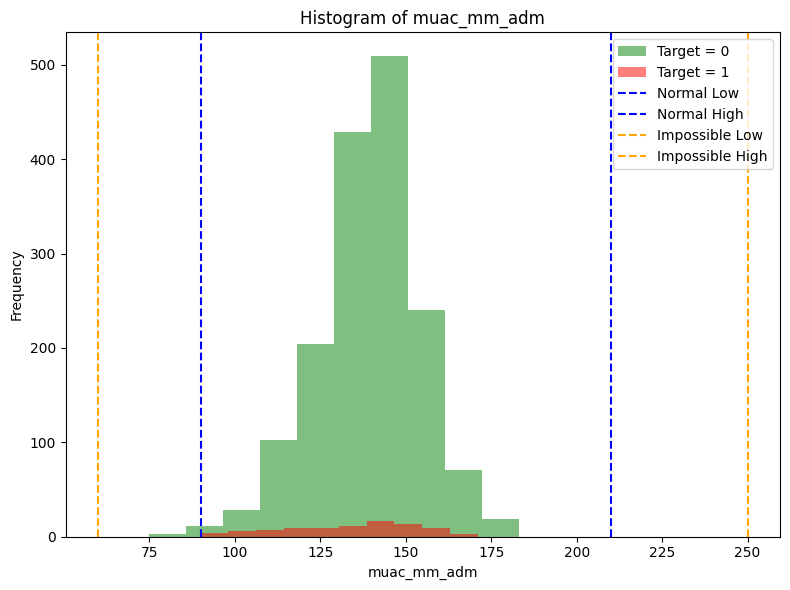

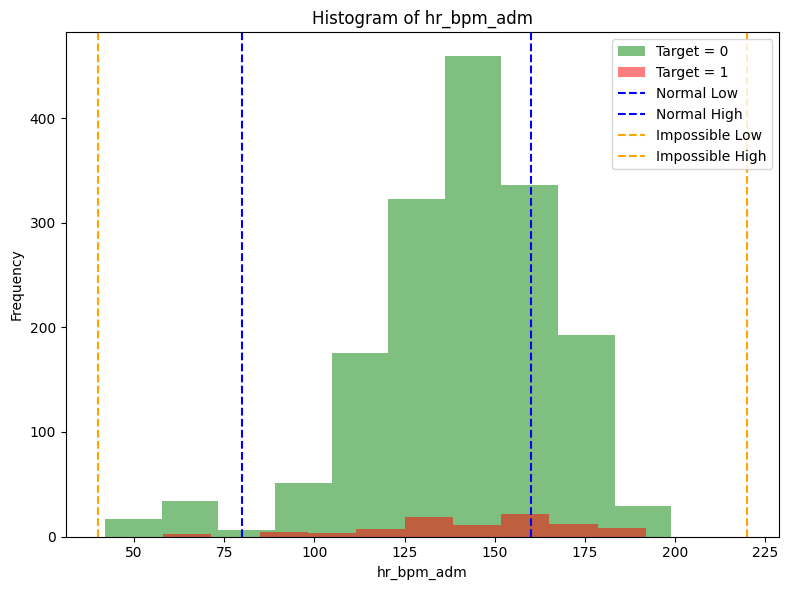

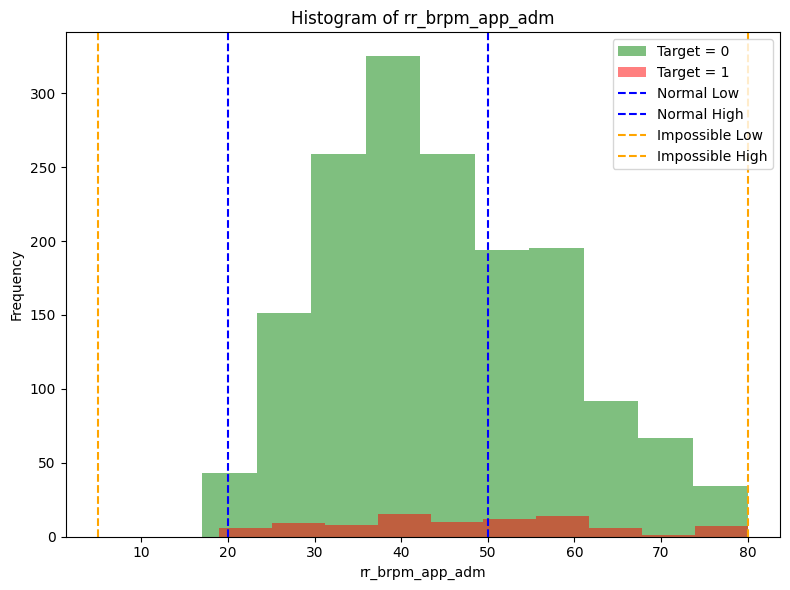

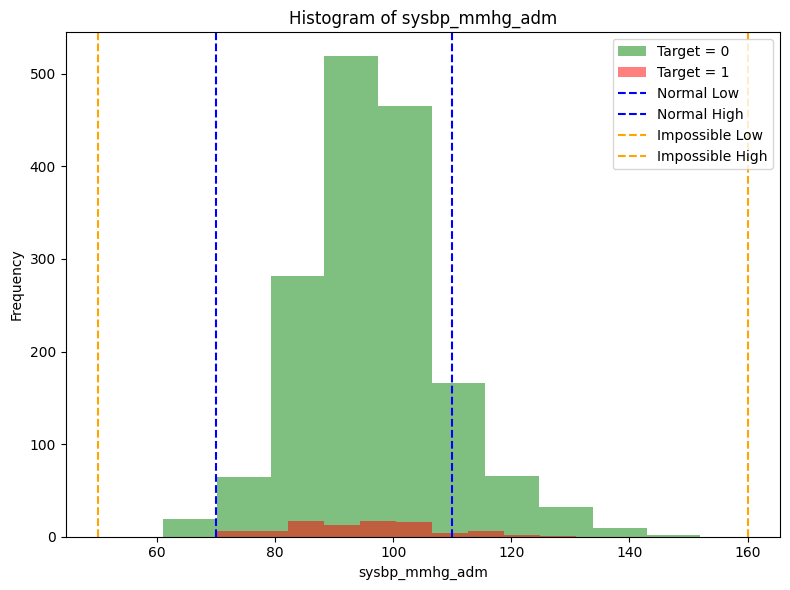

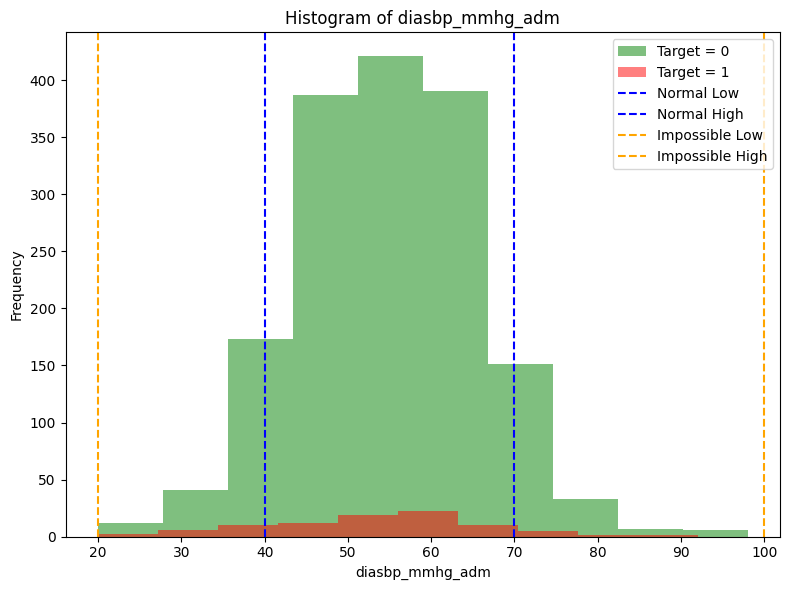

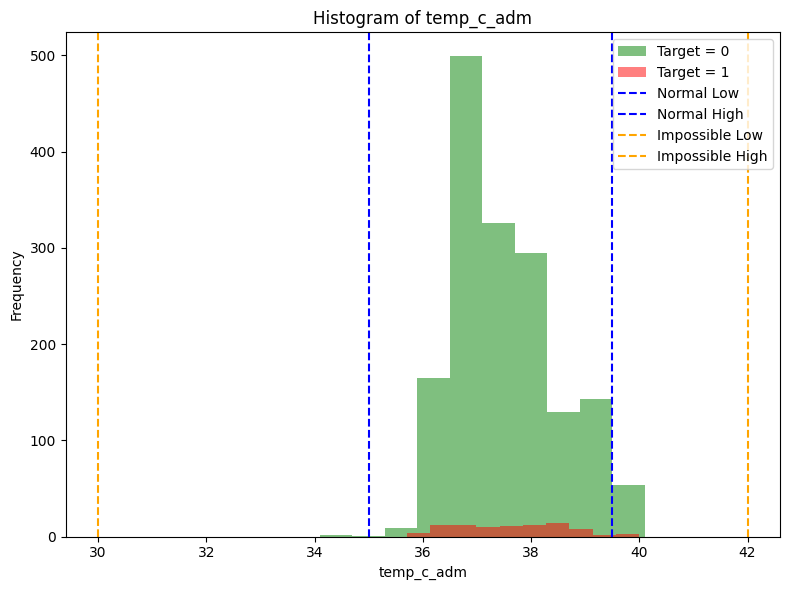

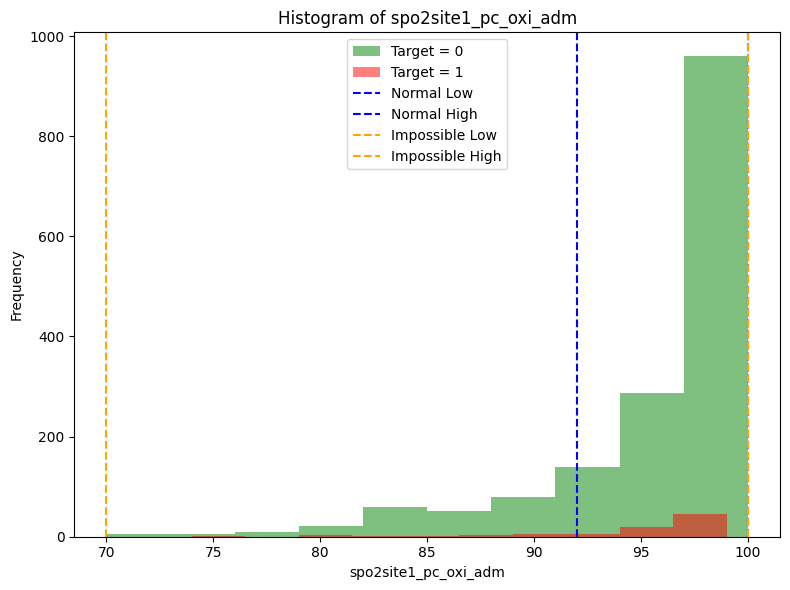

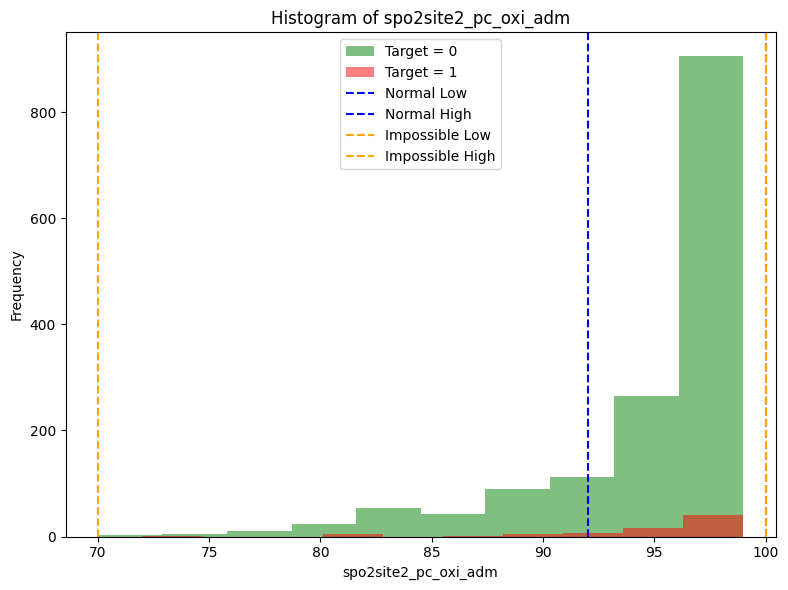

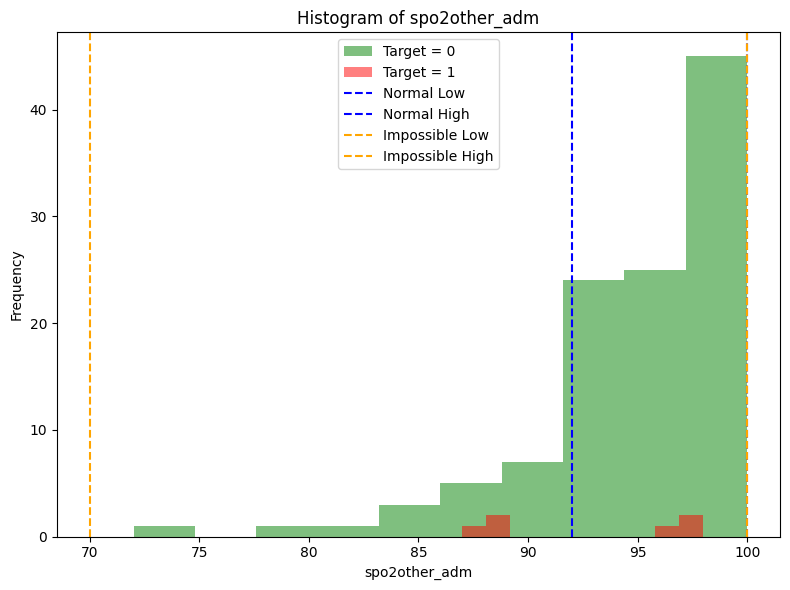

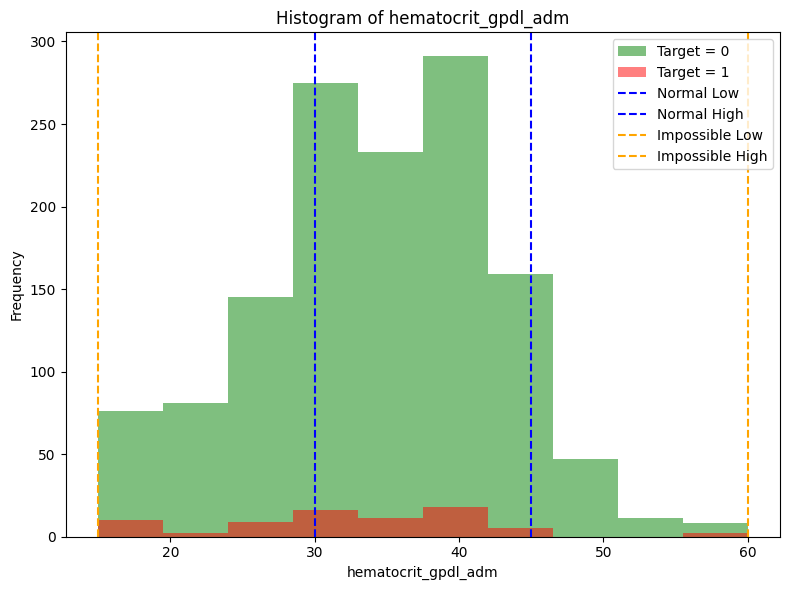

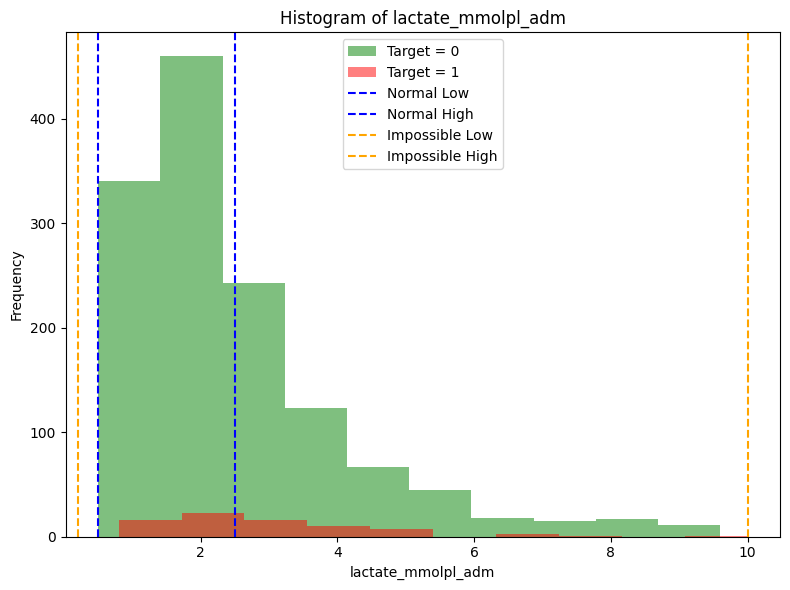

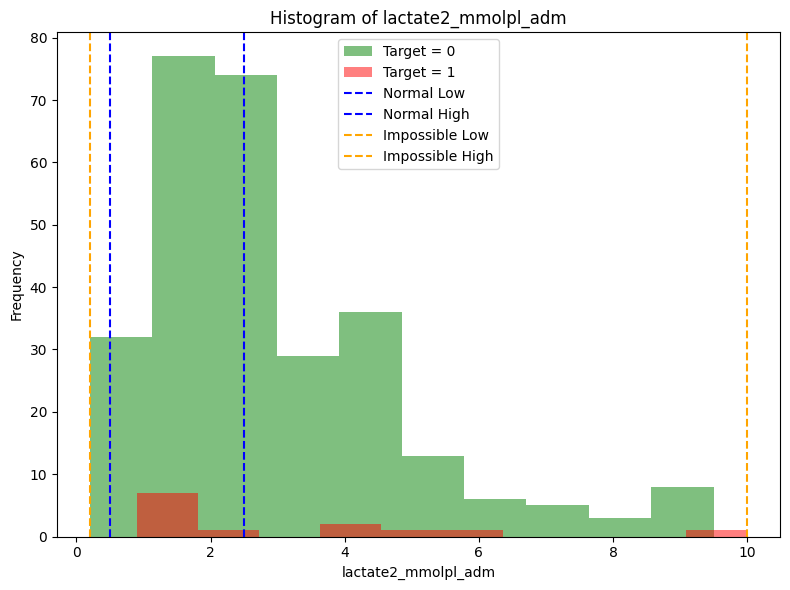

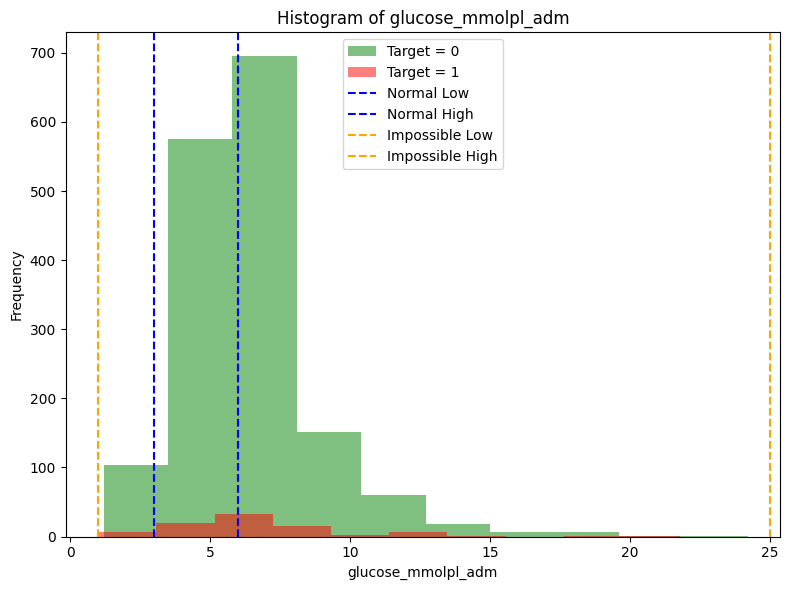

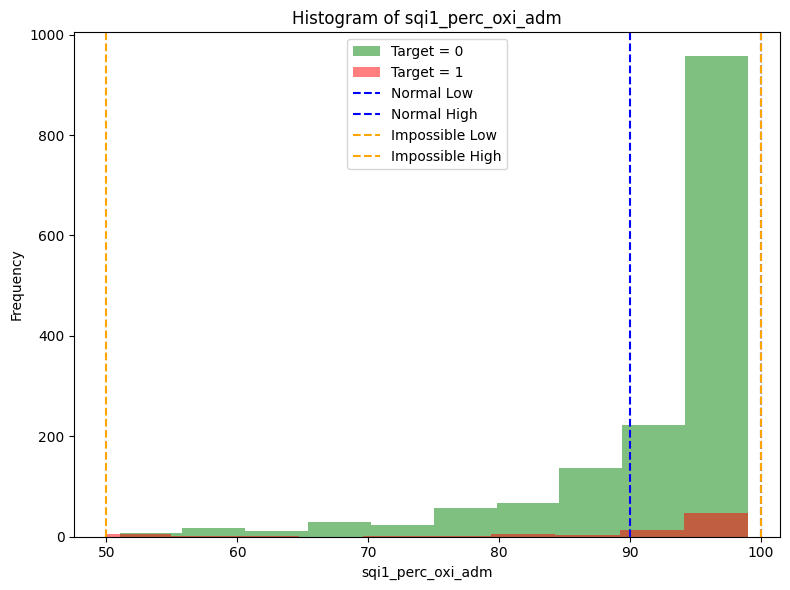

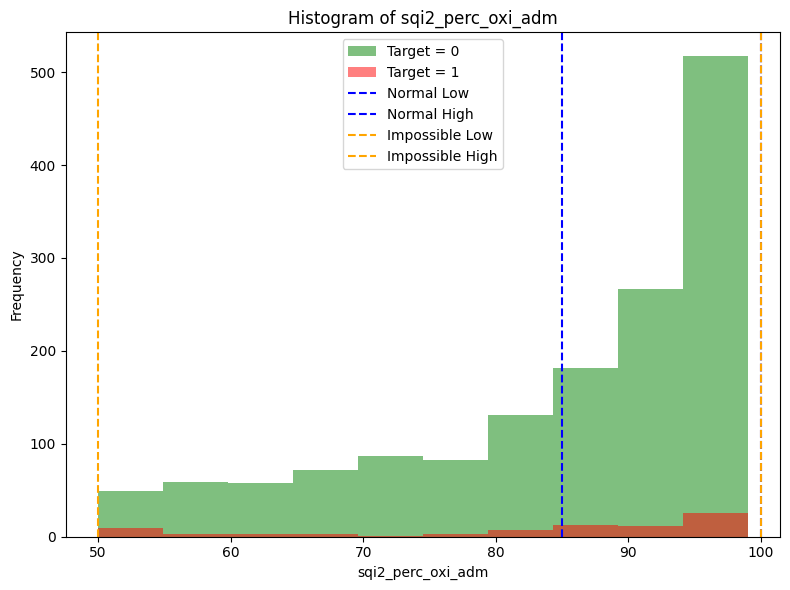

In [175]:
plot_outliers(tmp, fringe_boundaries)

In [179]:
!mkdir tmp_datasets

In [180]:
tmp.to_csv("tmp_datasets/outlier_removed.csv", index=False)
pd.read_csv("tmp_datasets/outlier_removed.csv")

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,alivechildren_adm,deadchildren_adm,hematocrit_gpdl_adm,lactate_mmolpl_adm,lactate2_mmolpl_adm,glucose_mmolpl_adm,sqi1_perc_oxi_adm,sqi2_perc_oxi_adm,inhospital_mortality,Outlier_trimmed
0,29.9,86.8,11.00,162.0,149.0,35.0,89.0,49.0,38.5,98.0,...,2.0,0.0,36.0,3.4,NaN,5.6,98.0,91.0,0,False
1,25.9,89.0,14.00,156.0,143.0,30.0,104.0,59.0,36.7,98.0,...,2.0,0.0,NaN,NaN,0.8,9.5,99.0,99.0,0,False
2,23.0,84.0,9.90,140.0,140.0,49.0,70.0,41.0,38.2,84.0,...,1.0,1.0,40.0,NaN,3.0,15.3,99.0,83.0,0,False
3,14.6,79.0,7.59,125.0,149.0,52.0,105.0,46.0,38.0,100.0,...,3.0,0.0,30.0,0.8,NaN,5.9,88.0,74.0,0,False
4,41.0,95.0,13.00,152.0,128.0,56.0,93.0,51.0,38.1,94.0,...,4.0,0.0,24.0,0.8,NaN,6.5,96.0,94.0,0,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1706,24.2,68.7,10.00,158.0,141.0,33.0,92.0,58.0,36.7,98.0,...,1.0,0.0,30.0,1.2,NaN,2.7,90.0,86.0,0,False
1707,12.2,66.8,5.00,105.0,150.0,61.0,101.0,56.0,37.0,86.0,...,1.0,0.0,36.0,2.8,NaN,5.7,98.0,95.0,0,False
1708,22.6,73.0,8.10,125.0,168.0,52.0,106.0,67.0,37.6,97.0,...,5.0,0.0,28.0,2.3,NaN,4.2,99.0,94.0,0,False
1709,9.3,71.0,5.30,95.0,136.0,61.0,91.0,55.0,38.2,87.0,...,7.0,1.0,32.0,NaN,2.5,5.3,92.0,94.0,0,False
